# Dar_012 — Joint environmental context and candidate/phase evidence

**Question:** Which environmental quantities are co-located, what is actually supported
at the same observed centers, and can spatial aggregation disguise missing thermal cohorts?

Use only completed local Dar_001/002 outputs (D01–D06 context). No downloads, mission
defaults, equipment limits, interpolation, suitability weights or pass/fail thresholds.
References: Dar_001/002 native-center/phase rules, Dar_006 quality context, and Stage 3/4
in `outline.md`. This notebook creates descriptive inputs, not eligibility decisions.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "env_algo_task/EDA/shared"), str(ROOT / "env_algo_task/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA=ROOT/'env_algo_task/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import (CONTEXT,PREDICTORS,BLOCK_KEYS,accepted_input,assign_blocks,spatial_blocks,
    validate_observations,distinct_context,context_features,thermal_features,phase_metadata,
    complete_phase_table,block_coverage,pairwise_spearman,sampled_condition_runs)
import decision_eda
def short(region):return region.split('_',2)[-1].replace('_',' ')
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def findings(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)

## Grains and support
- Static context is counted **once per native Diviner center**, never once per repeated phase row.
- Thermal quantities are grouped by **region/block and source phase product**. Local-hour
  means are circular; source products are not chronological dates or mission maxima.
- A **1,200 m globally aligned analysis block** is a grouping of source centers, not a CNN
  input grid, a fully measured footprint or a confirmed usable area. Boundary blocks are clipped
  to original SDEM rectangles. Blocks with no observed thermal centers remain in the index.
- `context_*` fields summarize the union of observed centers; `paired_*` fields use that
  phase's usable thermal centers. A missing thermal phase has NaN temperature, not zero;
  independent static context is retained where sampled.
- Compare “some thermal center in each common product” against “the same center in every
  common product.” These are different completeness conditions.
- Solar/Earth means being co-located does not mean their favorable states occur simultaneously.
  Existing technical pixel joins do not establish physical co-registration.

Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Leibnitz Beta Plateau centers: 4422 blocks: 196 phase rows: 28224
Malapert Massif centers: 7569 blocks: 342 phase rows: 49248
deGerlache Kocher Massif centers: 6972 blocks: 306 phase rows: 44064
Haworth centers: 15500 blocks: 650 phase rows: 93600
Faustini Rim A centers: 6972 blocks: 306 phase rows: 44064
deGerlache Rim 2 centers: 6889 blocks: 306 phase rows: 44064
Connecting Ridge Extension centers: 7056 blocks: 324 phase rows: 46656


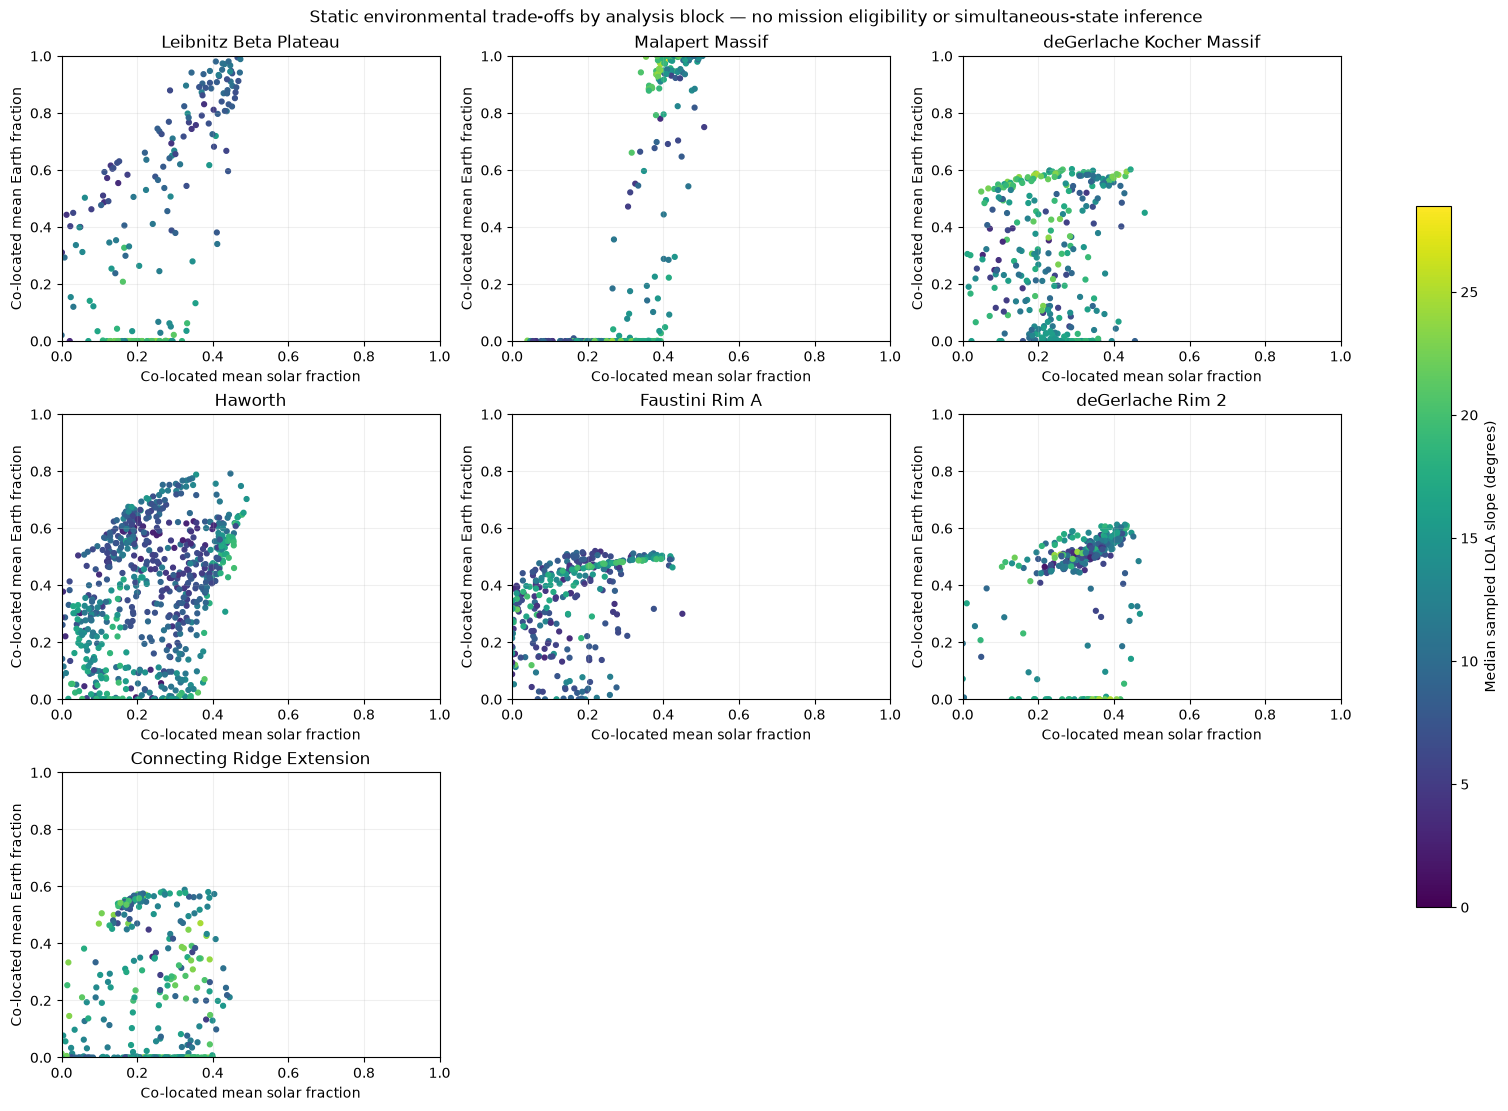

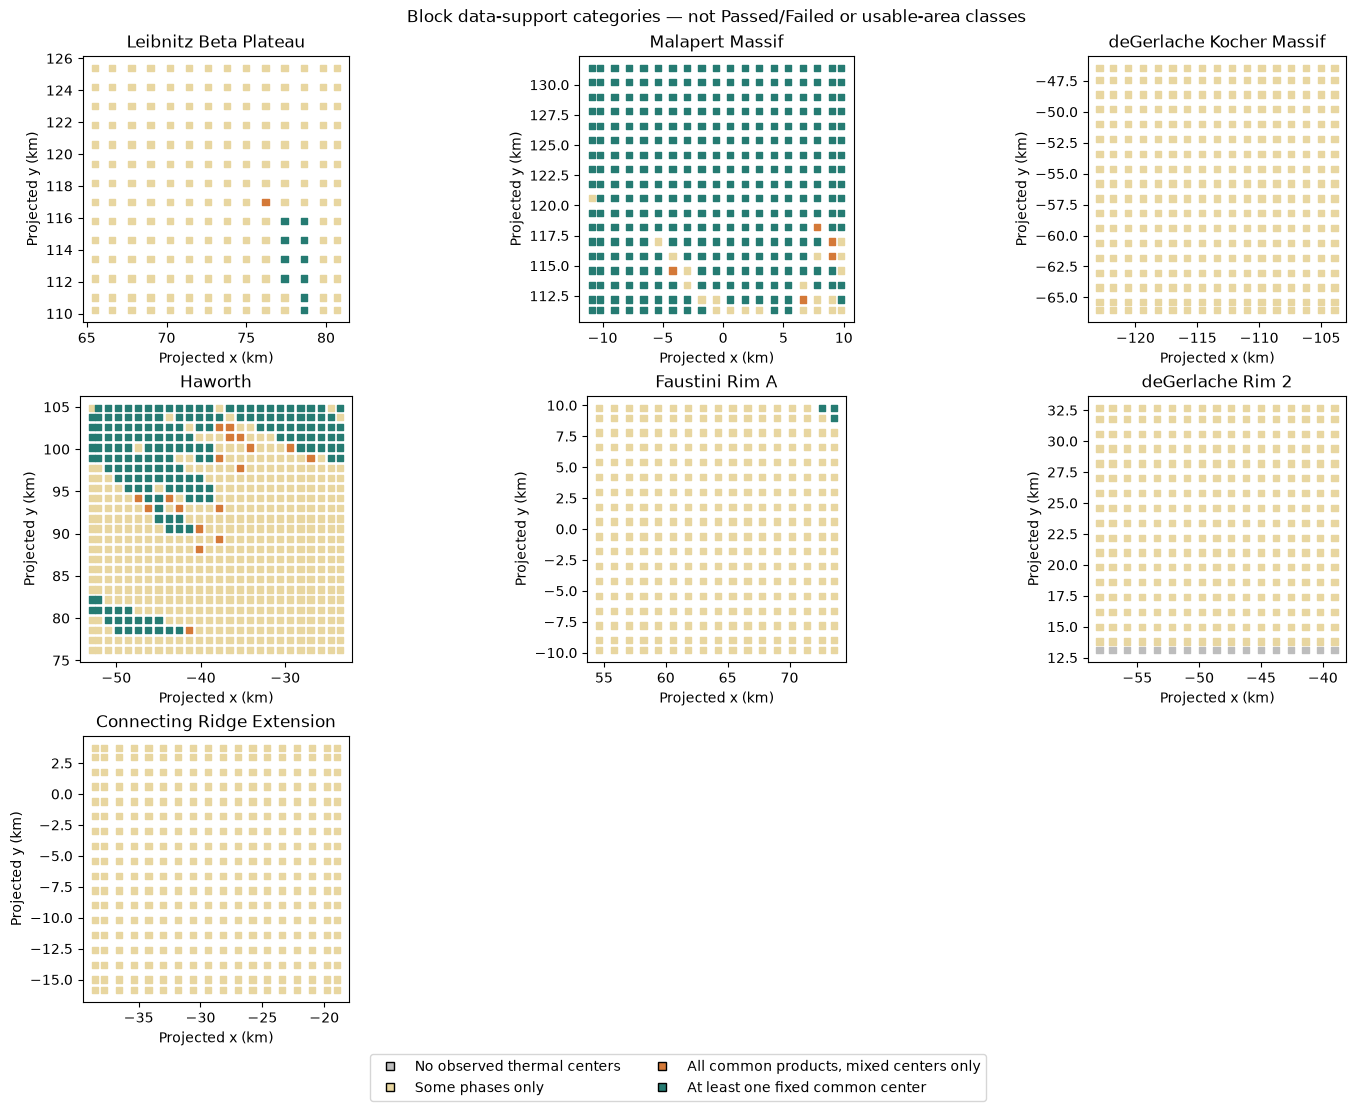

{'selected_regions': 7,
 'selected_products': 144,
 'common_products': 17,
 'observed_native_centers': 55380,
 'usable_center_product_rows': 4825369,
 'indexed_blocks': 2430,
 'blocks_without_observed_centers': 17,
 'candidate_phase_rows': 349920,
 'empty_candidate_phase_rows': 132244,
 'blocks_with_all_common_products_somewhere': 524,
 'blocks_with_fixed_common_centers': 500,
 'mixed_center_only_complete_blocks': 24,
 'limits': ['Point-context lookup, not physical co-registration or whole-footprint coverage',
  'Static mean co-location is not concurrent power/contact availability',
  'No equipment profile, hard pass or candidate score inferred']}

,region,indexed_blocks,blocks_with_any_thermal,blocks_with_any_center_in_all_common_products,blocks_with_fixed_common_centers,mixed_centers_only_blocks
0,A3CLR22_10_Leibnitz_Beta_Plateau,196,196,11,10,1
1,A3CLR22_11_Malapert_Massif,342,342,320,315,5
2,A3CLR22_12_deGerlache_Kocher_Massif,306,306,0,0,0
3,A3CLR22_2_Haworth,650,650,190,172,18
4,A3CLR22_3_Faustini_Rim_A,306,306,3,3,0
5,A3CLR22_4_deGerlache_Rim_2,306,289,0,0,0
6,A3CLR22_5_Connecting_Ridge_Extension,324,324,0,0,0


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\env_algo_task\data\processed\analysis\dar_012_joint_environment\20261109T142652747949Z_23fd8b


In [2]:
ENV_RUN_ID=None
BLOCK_WIDTH_M=1200
REGION_LIMIT=None  # Set 1 for a representative first run; None selects all seven regions.
environment_run=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment',ENV_RUN_ID)
env_provenance=json.loads((environment_run/'provenance.json').read_text())
declared_thermal=(ROOT/env_provenance['config']['thermal_run']).resolve()
thermal_run=latest_completed_run(ROOT,'analysis/dar_001_temperature_local_time',declared_thermal.name)
if thermal_run!=declared_thermal:raise ValueError('Unexpected thermal source path')
config={'environment_run':str(environment_run.relative_to(ROOT)),'thermal_run':str(thermal_run.relative_to(ROOT)),
    'block_width_m':BLOCK_WIDTH_M,'region_limit':REGION_LIMIT,'scope':'descriptive center/block/phase context only',
    'physical_coregistration':'not established','eligibility_or_area_assessment':False}
with Run(ROOT,'analysis/dar_012_joint_environment',config,'Moon/Environmental_Context/Dar_012_joint_environmental_context.ipynb') as run:
    run.input(Path(decision_eda.__file__))
    source_coverage=pd.read_csv(accepted_input(run,thermal_run,'product_coverage.csv'))
    source_findings=json.loads(accepted_input(run,thermal_run,'findings.json').read_text())
    footprints=json.loads(accepted_input(run,thermal_run,'region_footprints.json').read_text())
    products=sorted(source_coverage.source_product.unique());common=source_findings['common_products']
    if not set(common).issubset(products):raise ValueError('Common product selection is inconsistent')
    regions=list(footprints)
    if REGION_LIMIT is not None:
        if not isinstance(REGION_LIMIT,int) or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region limit')
        regions=regions[:REGION_LIMIT]
    footprints={k:footprints[k] for k in regions};run.record['config']['selected_regions']=regions
    columns=['region','source_product','clon','clat','x_m','y_m','tbol','local_time_h',
             'usable','valid_temperature','complete_common_cohort',*CONTEXT]
    block_parts=[];region_parts=[];center_parts=[];block_context_parts=[]
    for region in regions:
        path=accepted_input(run,environment_run,f'paired_observations/{region}.csv.gz')
        observations=pd.read_csv(path,usecols=columns)
        validate_observations(observations)
        expected_rows=source_coverage.loc[source_coverage.region.eq(region),'selected_rows'].sum()
        if len(observations)!=expected_rows or set(observations.region)!={region}:raise ValueError('Unexpected regional selection')
        if set(observations.source_product)-set(products):raise ValueError('Unknown source product')
        centers=assign_blocks(distinct_context(observations),BLOCK_WIDTH_M)
        centers.to_csv(run.path(f'native_centers/{region}.csv.gz'),index=False,compression={'method':'gzip','mtime':0,'compresslevel':3})
        center_parts.append(centers)
        observed_context=context_features(centers,BLOCK_KEYS)
        grid=spatial_blocks({region:footprints[region]},BLOCK_WIDTH_M)
        context=grid.merge(observed_context,on=BLOCK_KEYS,how='left',validate='one_to_one')
        if len(observed_context)!=context.observed_center_union.notna().sum():raise ValueError('Observed center outside indexed footprint')
        for field in ['observed_center_union','fixed_common_centers','joint_context_centers','context_zero_spot_centers','context_finite_spot_centers']:
            context[field]=context[field].fillna(0).astype('int64')
        context['context_data_status']=np.where(context.observed_center_union.gt(0),'sampled_at_observed_centers','not_sampled_without_thermal_centers')
        blocked=assign_blocks(observations,BLOCK_WIDTH_M)
        thermal=thermal_features(blocked,[*BLOCK_KEYS,'source_product'],common)
        table=complete_phase_table(thermal,context,BLOCK_KEYS,products,common)
        block_parts.append(table);block_context_parts.append(context)
        region_context=context_features(centers,['region'])
        region_thermal=thermal_features(observations,['region','source_product'],common)
        region_parts.append(complete_phase_table(region_thermal,region_context,['region'],products,common))
        print(short(region),'centers:',len(centers),'blocks:',len(context),'phase rows:',len(table))
    all_centers=pd.concat(center_parts,ignore_index=True)
    phase_table=pd.concat(block_parts,ignore_index=True);block_context=pd.concat(block_context_parts,ignore_index=True)
    regional=pd.concat(region_parts,ignore_index=True)
    coverage=block_coverage(phase_table,block_context,products,common)
    phase_table.to_csv(run.path('candidate_phase_features.csv.gz'),index=False,compression={'method':'gzip','mtime':0,'compresslevel':3})
    block_context.to_csv(run.path('candidate_block_context.csv'),index=False)
    regional.to_csv(run.path('region_phase_features.csv'),index=False)
    all_centers.to_csv(run.path('native_center_context.csv.gz'),index=False,compression={'method':'gzip','mtime':0,'compresslevel':3})
    coverage.to_csv(run.path('candidate_block_coverage.csv'),index=False)
    summary=coverage.assign(has_any=coverage.products_with_any_center.gt(0),has_fixed=coverage.fixed_common_centers.gt(0)).groupby('region').agg(
        indexed_blocks=('block_x','size'),blocks_with_any_thermal=('has_any','sum'),
        blocks_with_any_center_in_all_common_products=('all_common_products_have_some_center','sum'),
        blocks_with_fixed_common_centers=('has_fixed','sum'),mixed_centers_only_blocks=('mixed_centers_only_completeness','sum')).reset_index()
    summary.to_csv(run.path('regional_joint_coverage_summary.csv'),index=False)
    hist=all_centers[['region','solar_visibility','earth_visibility']].copy()
    for field in ['solar_visibility','earth_visibility']:
        hist[field+'_bin']=pd.cut(hist[field],[0,.25,.5,.75,1],include_lowest=True).astype(str)
    hist.groupby(['region','solar_visibility_bin','earth_visibility_bin']).size().rename('observed_centers').to_csv(run.path('co_located_visibility_distributions.csv'))
    source_grid=pd.read_csv(accepted_input(run,environment_run,'join_coverage.csv'))
    dictionary={'keys':['region','block_x','block_y','source_product'],'analysis_block_width_m':BLOCK_WIDTH_M,
        'thermal_native_support_m':240,'source_raster_units_and_resolutions':source_grid[['variable','unit','source_resolution_m']].drop_duplicates().to_dict('records'),
        'context_prefix':'equal weight over distinct observed source centers; not full raster/area coverage',
        'paired_prefix':'phase-specific usable thermal centers; changing cohorts remain explicit',
        'thermal_quantiles':'quantiles of phase-average surface brightness temperature, K; not confidence intervals or extremes',
        'missing_temperatures':'NaN; counts may be zero; no implicit equipment pass',
        'time_support':'thermal cumulative phase bins and static modeled maps are not contemporaneous time series',
        'registration':'containing native pixel technical lookup; physical co-registration not established',
        'algorithm_use':'descriptive inputs only; no mandatory status, weight, equipment limit or preference score invented'}
    run.path('feature_contract.json').write_text(json.dumps(dictionary,indent=2),encoding='utf-8')
    fig,axes=plt.subplots(3,3,figsize=(15,11),layout='constrained')
    color_max=max(float(block_context.context_median_slope_deg.max()),1.)
    for ax,region in zip(axes.flat,regions):
        part=block_context.loc[block_context.region.eq(region)]
        im=ax.scatter(part.context_mean_solar_fraction,part.context_mean_earth_fraction,c=part.context_median_slope_deg,
                      s=12,cmap='viridis',vmin=0,vmax=color_max)
        ax.set(title=short(region),xlabel='Co-located mean solar fraction',ylabel='Co-located mean Earth fraction',xlim=(0,1),ylim=(0,1));ax.grid(alpha=.2)
    for ax in list(axes.flat)[len(regions):]:ax.set_visible(False)
    fig.colorbar(im,ax=list(axes.flat)[:len(regions)],label='Median sampled LOLA slope (degrees)',shrink=.7)
    fig.suptitle('Static environmental trade-offs by analysis block — no mission eligibility or simultaneous-state inference')
    savefig(run,fig,'joint_visibility_terrain_context')
    from matplotlib.colors import ListedColormap,BoundaryNorm
    from matplotlib.lines import Line2D
    fig,axes=plt.subplots(3,3,figsize=(15,11),layout='constrained')
    mapped=coverage.merge(block_context[[*BLOCK_KEYS,'block_mid_x_m','block_mid_y_m']],on=BLOCK_KEYS,validate='one_to_one')
    mapped['support_category']=np.select([mapped.products_with_any_center.eq(0),mapped.fixed_common_centers.gt(0),mapped.mixed_centers_only_completeness],
        [0,3,2],default=1)
    colors=['#bdbdbd','#e8d6a0','#d47938','#257b72'];cmap=ListedColormap(colors)
    labels=['No observed thermal centers','Some phases only','All common products, mixed centers only','At least one fixed common center']
    for ax,region in zip(axes.flat,regions):
        part=mapped.loc[mapped.region.eq(region)]
        ax.scatter(part.block_mid_x_m/1000,part.block_mid_y_m/1000,c=part.support_category,cmap=cmap,norm=BoundaryNorm([-.5,.5,1.5,2.5,3.5],4),s=20,marker='s')
        ax.set(title=short(region),xlabel='Projected x (km)',ylabel='Projected y (km)',aspect='equal')
    for ax in list(axes.flat)[len(regions):]:ax.set_visible(False)
    fig.legend(handles=[Line2D([0],[0],marker='s',color='none',markerfacecolor=c,label=l) for c,l in zip(colors,labels)],loc='outside lower center',ncol=2)
    fig.suptitle('Block data-support categories — not Passed/Failed or usable-area classes')
    savefig(run,fig,'joint_support_categories')
    assert len(phase_table)==len(block_context)*len(products)
    assert phase_table.usable_rows.sum()==regional.usable_rows.sum()
    assert phase_table.loc[phase_table.usable_rows.eq(0),'tbol_median_K'].isna().all()
    assert not ((coverage.fixed_common_centers>0)&~coverage.all_common_products_have_some_center).any()
    findings(run,{'selected_regions':len(regions),'selected_products':len(products),'common_products':len(common),
        'observed_native_centers':len(all_centers),'usable_center_product_rows':int(phase_table.usable_rows.sum()),
        'indexed_blocks':len(block_context),'blocks_without_observed_centers':int(block_context.observed_center_union.eq(0).sum()),
        'candidate_phase_rows':len(phase_table),'empty_candidate_phase_rows':int(phase_table.usable_rows.eq(0).sum()),
        'blocks_with_all_common_products_somewhere':int(coverage.all_common_products_have_some_center.sum()),
        'blocks_with_fixed_common_centers':int(coverage.fixed_common_centers.gt(0).sum()),
        'mixed_center_only_complete_blocks':int(coverage.mixed_centers_only_completeness.sum()),
        'limits':['Point-context lookup, not physical co-registration or whole-footprint coverage',
                  'Static mean co-location is not concurrent power/contact availability','No equipment profile, hard pass or candidate score inferred']})
    display(summary)
OUT=run.directory;print('Completed:',OUT)

## Algorithm handoff
Use the explicit grain, units, phase identifiers and source/coverage contract. Independent
static context stays available even where thermal evidence is absent; missing temperature
is not a low temperature. A block that mixes different observed centers across phases
must not be represented as a fixed fully observed thermal cohort. No eligibility area or
mission ranking is computed. Keep environmental features separate from terrain CNN inputs.